In [1]:
from pyspark.sql import SparkSession

spark = (
    SparkSession.builder
    .master("local[*]")
    .appName("AQI-Analytics")
    .config("spark.driver.memory", "4g")
    .getOrCreate()
)

df = spark.read.csv("station_hour.csv", header=True, inferSchema=True)

print("Rows:", df.count())
df.printSchema()
df.show(5)

Using Spark's default log4j profile: org/apache/spark/log4j2-defaults.properties
26/10/18 11:34:09 WARN Utils: Your hostname, Swarika, resolves to a loopback address: 127.0.1.1; using 10.255.255.254 instead (on interface lo)
26/10/18 11:34:09 WARN Utils: Set SPARK_LOCAL_IP if you need to bind to another address
Using Spark's default log4j profile: org/apache/spark/log4j2-defaults.properties
Setting default log level to "WARN".
To adjust logging level use sc.setLogLevel(newLevel). For SparkR, use setLogLevel(newLevel).
/home/swarika/aqi-env/lib/python3.14/site-packages/pyspark/testing/utils.py:127: FutureWarning: PySpark does not yet fully support pandas >= 3.0.0. Some features may not work correctly. It is recommended to use pandas < 3.0.0 for now.
  require_minimum_pandas_version()
26/10/18 11:34:10 WARN NativeCodeLoader: Unable to load native-hadoop library for your platform... using builtin-java classes where applicable
                                                               

Rows: 2589083
root
 |-- StationId: string (nullable = true)
 |-- Datetime: timestamp (nullable = true)
 |-- PM2.5: double (nullable = true)
 |-- PM10: double (nullable = true)
 |-- NO: double (nullable = true)
 |-- NO2: double (nullable = true)
 |-- NOx: double (nullable = true)
 |-- NH3: double (nullable = true)
 |-- CO: double (nullable = true)
 |-- SO2: double (nullable = true)
 |-- O3: double (nullable = true)
 |-- Benzene: double (nullable = true)
 |-- Toluene: double (nullable = true)
 |-- Xylene: double (nullable = true)
 |-- AQI: double (nullable = true)
 |-- AQI_Bucket: string (nullable = true)

+---------+-------------------+-----+------+----+-----+-----+-----+---+-----+------+-------+-------+------+----+----------+
|StationId|           Datetime|PM2.5|  PM10|  NO|  NO2|  NOx|  NH3| CO|  SO2|    O3|Benzene|Toluene|Xylene| AQI|AQI_Bucket|
+---------+-------------------+-----+------+----+-----+-----+-----+---+-----+------+-------+-------+------+----+----------+
|    AP001|2017-

In [2]:
from pyspark.sql import functions as F
from pyspark.sql.types import (StructType, StructField, StringType,
                               TimestampType, DoubleType)

schema = StructType([
    StructField("StationId", StringType()),
    StructField("Datetime", TimestampType()),
    StructField("PM25", DoubleType()),
    StructField("PM10", DoubleType()),
    StructField("NO", DoubleType()),
    StructField("NO2", DoubleType()),
    StructField("NOx", DoubleType()),
    StructField("NH3", DoubleType()),
    StructField("CO", DoubleType()),
    StructField("SO2", DoubleType()),
    StructField("O3", DoubleType()),
    StructField("Benzene", DoubleType()),
    StructField("Toluene", DoubleType()),
    StructField("Xylene", DoubleType()),
    StructField("AQI", DoubleType()),
    StructField("AQI_Bucket", StringType()),
])

raw = spark.read.csv("station_hour.csv", header=True, schema=schema)

raw.write.mode("overwrite").parquet("station_hour_parquet")

df = spark.read.parquet("station_hour_parquet")
print("Rows:", df.count())
df.printSchema()

26/10/18 11:34:24 WARN CSVHeaderChecker: CSV header does not conform to the schema.
 Header: StationId, Datetime, PM2.5, PM10, NO, NO2, NOx, NH3, CO, SO2, O3, Benzene, Toluene, Xylene, AQI, AQI_Bucket
 Schema: StationId, Datetime, PM25, PM10, NO, NO2, NOx, NH3, CO, SO2, O3, Benzene, Toluene, Xylene, AQI, AQI_Bucket
Expected: PM25 but found: PM2.5
CSV file: file:///home/swarika/aqi-project/station_hour.csv
                                                                                

Rows: 2589083
root
 |-- StationId: string (nullable = true)
 |-- Datetime: timestamp (nullable = true)
 |-- PM25: double (nullable = true)
 |-- PM10: double (nullable = true)
 |-- NO: double (nullable = true)
 |-- NO2: double (nullable = true)
 |-- NOx: double (nullable = true)
 |-- NH3: double (nullable = true)
 |-- CO: double (nullable = true)
 |-- SO2: double (nullable = true)
 |-- O3: double (nullable = true)
 |-- Benzene: double (nullable = true)
 |-- Toluene: double (nullable = true)
 |-- Xylene: double (nullable = true)
 |-- AQI: double (nullable = true)
 |-- AQI_Bucket: string (nullable = true)



In [3]:
total = df.count()

null_pct = df.select([
    F.round(F.sum(F.col(c).isNull().cast("int")) / total * 100, 2).alias(c)
    for c in df.columns
])

null_pct.toPandas().T.rename(columns={0: "null_%"})

/home/swarika/aqi-env/lib/python3.14/site-packages/pyspark/sql/pandas/conversion.py:298: FutureWarning: PySpark does not yet fully support pandas >= 3.0.0. Some features may not work correctly. It is recommended to use pandas < 3.0.0 for now.
  require_minimum_pandas_version()
                                                                                

,null_%
StationId,0.00
Datetime,0.00
PM25,25.02
PM10,43.23
NO,21.39
NO2,20.43
NOx,18.96
NH3,47.76
CO,19.28
SO2,28.69


In [4]:
stations = spark.read.csv("stations.csv", header=True)
print(stations.count())
stations.show(5, truncate=False)

230
+---------+----------------------------------------------+-----------------+--------------+------+
|StationId|StationName                                   |City             |State         |Status|
+---------+----------------------------------------------+-----------------+--------------+------+
|AP001    |Secretariat, Amaravati - APPCB                |Amaravati        |Andhra Pradesh|Active|
|AP002    |Anand Kala Kshetram, Rajamahendravaram - APPCB|Rajamahendravaram|Andhra Pradesh|NULL  |
|AP003    |Tirumala, Tirupati - APPCB                    |Tirupati         |Andhra Pradesh|NULL  |
|AP004    |PWD Grounds, Vijayawada - APPCB               |Vijayawada       |Andhra Pradesh|NULL  |
|AP005    |GVM Corporation, Visakhapatnam - APPCB        |Visakhapatnam    |Andhra Pradesh|Active|
+---------+----------------------------------------------+-----------------+--------------+------+
only showing top 5 rows


In [5]:
df2 = (
    df.drop("Xylene")
    .join(stations.select("StationId", "StationName", "City", "State"),
          on="StationId", how="left")
    .withColumn("hour", F.hour("Datetime"))
    .withColumn("month", F.month("Datetime"))
    .withColumn("year", F.year("Datetime"))
    .withColumn("dayofweek", F.dayofweek("Datetime"))
    .withColumn("season",
        F.when(F.col("month").isin(12, 1, 2), "Winter")
         .when(F.col("month").isin(3, 4, 5), "Summer")
         .when(F.col("month").isin(6, 7, 8, 9), "Monsoon")
         .otherwise("Post-monsoon"))
)

df2.write.mode("overwrite").parquet("clean_parquet")
df2 = spark.read.parquet("clean_parquet")

print("Rows:", df2.count())
print("Rows with no city:", df2.filter(F.col("City").isNull()).count())
df2.groupBy("year").count().orderBy("year").show()
df2.groupBy("City").count().orderBy(F.desc("count")).show(30)

Rows: 2589083
Rows with no city: 0


+----+------+
|year| count|
+----+------+
|2015|177232|
|2016|234909|
|2017|322686|
|2018|615388|
|2019|776778|
|2020|462090|
+----+------+

+------------------+-------+
|              City|  count|
+------------------+-------+
|             Delhi|1087388|
|         Bengaluru| 287564|
|         Hyderabad| 209831|
|           Chennai| 153648|
|           Lucknow| 146210|
|            Mumbai| 131750|
|           Kolkata|  75717|
|            Jaipur|  74032|
|          Gurugram|  67804|
|             Patna|  64031|
|         Ahmedabad|  48192|
|     Visakhapatnam|  35053|
|Thiruvananthapuram|  29971|
|          Amritsar|  29269|
|        Jorapokhar|  28025|
|         Amaravati|  22784|
|      Brajrajnagar|  22468|
|           Talcher|  22161|
|          Guwahati|  12002|
|        Coimbatore|   9229|
|          Shillong|   7402|
|        Chandigarh|   7263|
|            Bhopal|   6903|
|             Kochi|   3854|
|         Ernakulam|   3852|
|            Aizawl|   2680|
+-----------------

In [6]:
df2.agg(F.min("Datetime"), F.max("Datetime")).show(truncate=False)
df2.groupBy("year").agg(F.countDistinct("StationId").alias("stations")).orderBy("year").show()

+-------------------+-------------------+
|min(Datetime)      |max(Datetime)      |
+-------------------+-------------------+
|2015-01-01 01:00:00|2020-07-01 00:00:00|
+-------------------+-------------------+

+----+--------+
|year|stations|
+----+--------+
|2015|      25|
|2016|      29|
|2017|      50|
|2018|      78|
|2019|     102|
|2020|     110|
+----+--------+



In [11]:
city_rank = (
    df5.filter(F.col("AQI").isNotNull())
    .groupBy("City")
    .agg(F.count("*").alias("readings"),
         F.round(F.avg("AQI"), 1).alias("avg_AQI"),
         F.round(F.avg("PM25"), 1).alias("avg_PM25"))
    .filter(F.col("readings") >= 10000)
    .orderBy(F.desc("avg_AQI"))
)
city_rank.show(30)

+------------------+--------+-------+--------+
|              City|readings|avg_AQI|avg_PM25|
+------------------+--------+-------+--------+
|             Delhi|  812215|  236.6|   110.1|
|           Lucknow|  120777|  217.0|   110.0|
|             Patna|   47459|  212.9|   102.3|
|          Gurugram|   52914|  210.8|   104.7|
|           Talcher|   15008|  177.6|    65.5|
|        Jorapokhar|   17430|  160.0|    64.0|
|      Brajrajnagar|   16047|  151.4|    66.8|
|          Guwahati|   11740|  140.2|    61.6|
|            Jaipur|   70494|  134.6|    55.0|
|           Kolkata|   70173|  132.6|    58.8|
|          Amritsar|   25840|  120.5|    54.4|
|     Visakhapatnam|   26766|  117.7|    48.3|
|           Chennai|  111696|  112.8|    48.3|
|            Mumbai|   90119|  103.7|    37.4|
|         Hyderabad|  163603|  100.5|    44.4|
|         Amaravati|   19377|   95.6|    38.8|
|         Bengaluru|  219523|   91.4|    34.4|
|Thiruvananthapuram|   27265|   75.1|    28.6|
+------------

/home/swarika/aqi-env/lib/python3.14/site-packages/pyspark/sql/pandas/conversion.py:298: FutureWarning: PySpark does not yet fully support pandas >= 3.0.0. Some features may not work correctly. It is recommended to use pandas < 3.0.0 for now.
  require_minimum_pandas_version()


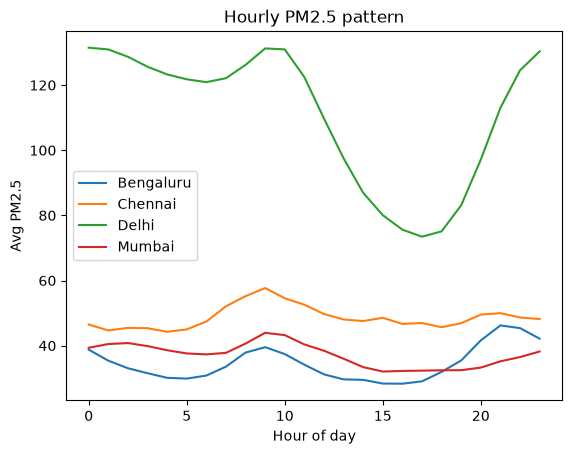

In [15]:
import matplotlib.pyplot as plt

hourly = (
    df5.filter(F.col("City").isin("Delhi", "Mumbai", "Bengaluru", "Chennai"))
    .groupBy("City", "hour").agg(F.avg("PM25").alias("pm25"))
    .orderBy("City", "hour")
    .toPandas()
)

for city, g in hourly.groupby("City"):
    plt.plot(g["hour"], g["pm25"], label=city)
plt.xlabel("Hour of day"); plt.ylabel("Avg PM2.5"); plt.legend()
plt.title("Hourly PM2.5 pattern"); plt.show()

In [16]:
season_tbl = (
    df2.filter(F.col("City").isin("Delhi", "Mumbai", "Bengaluru", "Chennai", "Kolkata", "Lucknow"))
    .groupBy("City").pivot("season", ["Winter", "Summer", "Monsoon", "Post-monsoon"])
    .agg(F.round(F.avg("AQI"), 1))
)
season_tbl.show()

+---------+------+------+-------+------------+
|     City|Winter|Summer|Monsoon|Post-monsoon|
+---------+------+------+-------+------------+
|  Lucknow| 317.2| 184.1|  113.5|       301.3|
|  Chennai| 117.8| 107.2|  111.5|       117.3|
|   Mumbai| 169.6|  84.8|   63.5|       117.6|
|  Kolkata| 234.8|  90.1|   55.8|       181.8|
|    Delhi| 329.2| 206.2|  145.0|       331.3|
|Bengaluru| 104.6|  98.3|   72.9|        94.6|
+---------+------+------+-------+------------+



In [17]:
cols = ["PM25", "PM10", "NO2", "CO", "SO2", "O3", "Benzene", "Toluene", "AQI"]

for name in ["Ahmedabad", "Delhi"]:
    print(name)
    df2.filter(F.col("City") == name).select(
        [F.round(F.avg(c), 1).alias(c) for c in cols]
    ).show()

df2.filter(F.col("City") == "Ahmedabad").groupBy("year").agg(
    F.count("AQI").alias("readings"), F.round(F.avg("AQI"), 1).alias("avg_AQI")
).orderBy("year").show()

Ahmedabad
+----+-----+----+----+----+----+-------+-------+-----+
|PM25| PM10| NO2|  CO| SO2|  O3|Benzene|Toluene|  AQI|
+----+-----+----+----+----+----+-------+-------+-----+
|67.3|111.5|59.5|22.0|52.8|39.1|    5.3|   27.5|453.5|
+----+-----+----+----+----+----+-------+-------+-----+

Delhi
+-----+-----+----+---+----+----+-------+-------+-----+
| PM25| PM10| NO2| CO| SO2|  O3|Benzene|Toluene|  AQI|
+-----+-----+----+---+----+----+-------+-------+-----+
|110.8|216.6|45.3|1.5|14.3|43.6|    3.6|   23.6|238.9|
+-----+-----+----+---+----+----+-------+-------+-----+

+----+--------+-------+
|year|readings|avg_AQI|
+----+--------+-------+
|2015|    6072|  308.4|
|2016|    2675|  301.9|
|2017|    1610|  564.5|
|2018|    8381|  625.1|
|2019|    8176|  517.3|
|2020|    4007|  241.1|
+----+--------+-------+



In [18]:
amd = df2.filter(F.col("City") == "Ahmedabad")
amd.groupBy("year").agg(
    F.round(F.avg("CO"), 1).alias("avg_CO"),
    F.round(F.expr("percentile_approx(CO, 0.5)"), 1).alias("median_CO"),
    F.round(F.max("CO"), 1).alias("max_CO")
).orderBy("year").show()

df2.filter(F.col("City") != "Ahmedabad").agg(
    F.round(F.avg("CO"), 2).alias("avg_CO_other_cities"),
    F.round(F.expr("percentile_approx(CO, 0.99)"), 2).alias("p99_CO_other_cities")
).show()

+----+------+---------+------+
|year|avg_CO|median_CO|max_CO|
+----+------+---------+------+
|2015|  12.7|      6.8| 331.0|
|2016|  15.4|      9.5| 423.8|
|2017|  29.5|      5.9| 498.6|
|2018|  33.0|     14.1| 494.9|
|2019|  25.8|     12.6| 476.0|
|2020|   8.1|      1.5| 428.7|
+----+------+---------+------+



[Stage 92:============================>                            (6 + 6) / 12]

+-------------------+-------------------+
|avg_CO_other_cities|p99_CO_other_cities|
+-------------------+-------------------+
|               1.19|               7.62|
+-------------------+-------------------+



In [19]:
df2.groupBy("StationId", "City").agg(
    F.round(F.avg("CO"), 1).alias("avg_CO")
).filter(F.col("avg_CO") > 5).orderBy(F.desc("avg_CO")).show()

+---------+---------+------+
|StationId|     City|avg_CO|
+---------+---------+------+
|    GJ001|Ahmedabad|  22.0|
+---------+---------+------+



In [20]:
bad = F.col("StationId") == "GJ001"

df3 = (
    df2
    .withColumn("CO",  F.when(bad, None).otherwise(F.col("CO")))
    .withColumn("AQI", F.when(bad, None).otherwise(F.col("AQI")))
    .withColumn("AQI_Bucket", F.when(bad, None).otherwise(F.col("AQI_Bucket")))
)

df3.write.mode("overwrite").parquet("clean_v2_parquet")
df3 = spark.read.parquet("clean_v2_parquet")
print("Rows:", df3.count())

Rows: 2589083


In [21]:
def period(y):
    return (F.col("Datetime") >= f"{y}-03-25") & (F.col("Datetime") < f"{y}-07-01")

has_pm = F.col("PM25").isNotNull()
s19 = df3.filter(period(2019) & has_pm).select("StationId").distinct()
s20 = df3.filter(period(2020) & has_pm).select("StationId").distinct()
common = s19.join(s20, "StationId")
print("Stations in both periods:", common.count())

covid = (
    df3.filter(has_pm)
    .join(common, "StationId")
    .filter(period(2019) | period(2020))
    .groupBy("City").pivot("year", [2019, 2020]).agg(F.round(F.avg("PM25"), 1))
    .withColumnRenamed("2019", "pm25_2019")
    .withColumnRenamed("2020", "pm25_2020")
    .withColumn("change_pct",
        F.round((F.col("pm25_2020") - F.col("pm25_2019")) / F.col("pm25_2019") * 100, 1))
    .orderBy("change_pct")
)
covid.show(40)

Stations in both periods: 87
+------------------+---------+---------+----------+
|              City|pm25_2019|pm25_2020|change_pct|
+------------------+---------+---------+----------+
|         Ahmedabad|     65.9|     29.0|     -56.0|
|          Gurugram|     88.5|     43.4|     -51.0|
|           Chennai|     42.1|     21.7|     -48.5|
|           Kolkata|     39.0|     21.0|     -46.2|
|         Bengaluru|     39.1|     21.7|     -44.5|
|     Visakhapatnam|     35.5|     20.2|     -43.1|
|          Amritsar|     49.3|     28.7|     -41.8|
|Thiruvananthapuram|     23.3|     13.7|     -41.2|
|        Coimbatore|     34.4|     20.3|     -41.0|
|             Delhi|     78.8|     47.9|     -39.2|
|           Lucknow|     90.8|     57.9|     -36.2|
|         Amaravati|     26.1|     17.3|     -33.7|
|            Jaipur|     51.4|     34.2|     -33.5|
|         Hyderabad|     35.9|     26.7|     -25.6|
|        Jorapokhar|     57.7|     45.3|     -21.5|
|          Guwahati|     41.5|     

In [22]:
chk = (
    df3.filter(F.col("PM25").isNotNull()).join(common, "StationId")
    .filter(period(2019) | period(2020))
    .groupBy("City").agg(F.countDistinct("StationId").alias("stations"),
                         F.count("*").alias("readings"))
    .orderBy("stations")
)
chk.show(40)

+------------------+--------+--------+
|              City|stations|readings|
+------------------+--------+--------+
|             Patna|       1|    2914|
|         Ahmedabad|       1|    4292|
|      Brajrajnagar|       1|    2592|
|         Amaravati|       1|    4242|
|          Amritsar|       1|    4360|
|        Coimbatore|       1|    2102|
|Thiruvananthapuram|       1|    3632|
|           Talcher|       1|    3211|
|        Jorapokhar|       1|    2155|
|          Guwahati|       1|    4539|
|     Visakhapatnam|       1|    4119|
|          Gurugram|       2|    8204|
|           Lucknow|       3|   13553|
|            Jaipur|       3|   13536|
|           Chennai|       4|   15243|
|           Kolkata|       4|   14376|
|         Hyderabad|       6|   24694|
|         Bengaluru|       8|   32394|
|            Mumbai|      10|   22330|
|             Delhi|      36|  155904|
+------------------+--------+--------+



In [23]:
diwali = {2015: "2015-11-11", 2016: "2016-10-30", 2017: "2017-10-19",
          2018: "2018-11-07", 2019: "2019-10-27"}

dd = (spark.createDataFrame([(y, d) for y, d in diwali.items()], ["year", "diwali"])
      .withColumn("diwali", F.to_date("diwali")))

x = (
    df3.filter(F.col("PM25").isNotNull())
    .join(dd, "year")
    .withColumn("offset", F.datediff(F.to_date("Datetime"), F.col("diwali")))
    .filter(F.col("offset").between(-5, 2))
    .withColumn("phase", F.when(F.col("offset") < 0, "before").otherwise("after"))
)

both = (x.groupBy("year", "StationId")
        .agg(F.countDistinct("phase").alias("n")).filter("n = 2")
        .select("year", "StationId"))
x = x.join(both, ["year", "StationId"])

diwali_res = (
    x.groupBy("City", "year").pivot("phase", ["before", "after"])
    .agg(F.round(F.avg("PM25"), 1))
    .withColumn("change_pct",
        F.round((F.col("after") - F.col("before")) / F.col("before") * 100, 1))
)

diwali_res.filter(F.col("City").isin("Delhi", "Lucknow", "Kolkata", "Mumbai", "Patna", "Gurugram")) \
    .orderBy("City", "year").show(40)

+--------+----+------+-----+----------+
|    City|year|before|after|change_pct|
+--------+----+------+-----+----------+
|   Delhi|2015| 234.1|256.2|       9.4|
|   Delhi|2016| 258.1|394.4|      52.8|
|   Delhi|2017| 142.2|249.8|      75.7|
|   Delhi|2018| 200.9|277.3|      38.0|
|   Delhi|2019| 133.3|258.4|      93.8|
|Gurugram|2016| 241.9|257.0|       6.2|
|Gurugram|2017|  94.7|203.0|     114.4|
|Gurugram|2018| 189.4|217.4|      14.8|
|Gurugram|2019| 117.5|215.5|      83.4|
| Kolkata|2018|  57.6|231.8|     302.4|
| Kolkata|2019|  47.5|109.7|     130.9|
| Lucknow|2015| 177.1|334.8|      89.0|
| Lucknow|2016| 144.1|309.3|     114.6|
| Lucknow|2017| 157.5|157.6|       0.1|
| Lucknow|2018| 158.7|282.0|      77.7|
| Lucknow|2019| 111.4|168.5|      51.3|
|  Mumbai|2018|  43.8| 97.2|     121.9|
|  Mumbai|2019|  22.8| 49.7|     118.0|
|   Patna|2015| 199.4|213.0|       6.8|
|   Patna|2016| 170.0|320.6|      88.6|
|   Patna|2017| 117.6| 70.3|     -40.2|
|   Patna|2018| 167.8|244.5|      45.7|


In [24]:
stn = (
    df3.filter(has_pm).join(common, "StationId")
    .filter(period(2019) | period(2020))
    .groupBy("StationId").pivot("year", [2019, 2020]).agg(F.avg("PM25"))
    .withColumn("change_pct", (F.col("2020") - F.col("2019")) / F.col("2019") * 100)
)

stn.agg(
    F.count("*").alias("stations"),
    F.sum((F.col("change_pct") < 0).cast("int")).alias("stations_fell"),
    F.round(F.expr("percentile_approx(change_pct, 0.5)"), 1).alias("median_change_pct")
).show()

+--------+-------------+-----------------+
|stations|stations_fell|median_change_pct|
+--------+-------------+-----------------+
|      87|           81|            -34.7|
+--------+-------------+-----------------+



In [25]:
# all stations together, per year
(x.groupBy("year").agg(
    F.countDistinct("StationId").alias("stations"),
    F.round(F.avg(F.when(F.col("phase") == "before", F.col("PM25"))), 1).alias("before"),
    F.round(F.avg(F.when(F.col("phase") == "after", F.col("PM25"))), 1).alias("after"))
 .withColumn("change_pct", F.round((F.col("after") - F.col("before")) / F.col("before") * 100, 1))
 .orderBy("year").show())

# stations behind each city-year row
(x.filter(F.col("City").isin("Delhi", "Lucknow", "Kolkata", "Mumbai", "Gurugram", "Patna"))
  .groupBy("City", "year").agg(F.countDistinct("StationId").alias("stations"))
  .orderBy("City", "year").show(40))

+----+--------+------+-----+----------+
|year|stations|before|after|change_pct|
+----+--------+------+-----+----------+
|2015|      17| 144.3|185.8|      28.8|
|2016|      13| 148.6|219.2|      47.5|
|2017|      26| 108.8|165.2|      51.8|
|2018|      73| 133.5|192.6|      44.3|
|2019|      94|  81.6|156.6|      91.9|
+----+--------+------+-----+----------+



+--------+----+--------+
|    City|year|stations|
+--------+----+--------+
|   Delhi|2015|       7|
|   Delhi|2016|       3|
|   Delhi|2017|      11|
|   Delhi|2018|      36|
|   Delhi|2019|      37|
|Gurugram|2016|       1|
|Gurugram|2017|       1|
|Gurugram|2018|       2|
|Gurugram|2019|       2|
| Kolkata|2018|       2|
| Kolkata|2019|       7|
| Lucknow|2015|       2|
| Lucknow|2016|       2|
| Lucknow|2017|       3|
| Lucknow|2018|       4|
| Lucknow|2019|       4|
|  Mumbai|2018|       1|
|  Mumbai|2019|      10|
|   Patna|2015|       1|
|   Patna|2016|       1|
|   Patna|2017|       1|
|   Patna|2018|       1|
|   Patna|2019|       1|
+--------+----+--------+



In [26]:
from pyspark.sql import functions as F

spark = SparkSession.builder.master("local[*]").appName("AQI-Analytics") \
    .config("spark.driver.memory", "4g").getOrCreate()
df3 = spark.read.parquet("clean_v2_parquet")

In [27]:
from pyspark.ml.feature import VectorAssembler, StandardScaler
from pyspark.ml.clustering import KMeans
from pyspark.ml.evaluation import ClusteringEvaluator

feats = ["PM25", "NO2", "SO2", "O3", "CO"]

prof = (
    df3.groupBy("StationId", "City")
    .agg(*[F.avg(c).alias(c) for c in feats], F.count("PM25").alias("n_pm25"))
    .filter(F.col("n_pm25") >= 2000)
    .dropna(subset=feats)
)
print("Stations clustered:", prof.count())

vec = VectorAssembler(inputCols=feats, outputCol="raw").transform(prof)
scaler = StandardScaler(inputCol="raw", outputCol="features",
                        withMean=True, withStd=True).fit(vec)
data = scaler.transform(vec).cache()

ev = ClusteringEvaluator(featuresCol="features", metricName="silhouette")
for k in range(2, 8):
    m = KMeans(k=k, seed=42, featuresCol="features").fit(data)
    print("k =", k, " silhouette =", round(ev.evaluate(m.transform(data)), 3))

Stations clustered: 91


netlib-blas: JNI_OnLoad: dlopen(libblas.so.3) failed: libblas.so.3: cannot open shared object file: No such file or directory
                                                                                

k = 2  silhouette = 0.572
k = 3  silhouette = 0.348
k = 4  silhouette = 0.558
k = 5  silhouette = 0.398
k = 6  silhouette = 0.273
k = 7  silhouette = 0.335


In [28]:
K = 4   # change after looking at the silhouette scores

model = KMeans(k=K, seed=42, featuresCol="features").fit(data)
clustered = model.transform(data).withColumnRenamed("prediction", "cluster")

# 1) Average pollutant levels per cluster
(clustered.groupBy("cluster")
 .agg(F.count("*").alias("stations"),
      *[F.round(F.avg(c), 1).alias(c) for c in feats])
 .orderBy("cluster").show())

# 2) Which cities fall in each cluster
(clustered.groupBy("cluster", "City").agg(F.count("*").alias("stations"))
 .orderBy("cluster", F.desc("stations")).show(60, truncate=False))

+-------+--------+-----+----+----+-----+---+
|cluster|stations| PM25| NO2| SO2|   O3| CO|
+-------+--------+-----+----+----+-----+---+
|      0|      27|112.3|47.1|13.2| 35.6|1.6|
|      1|       6| 93.2|32.0|23.7| 34.4|1.3|
|      2|      57| 45.7|24.2| 9.3| 32.8|0.8|
|      3|       1|120.6|71.1|19.8|228.2|1.4|
+-------+--------+-----+----+----+-----+---+

+-------+------------------+--------+
|cluster|City              |stations|
+-------+------------------+--------+
|0      |Delhi             |22      |
|0      |Lucknow           |3       |
|0      |Patna             |1       |
|0      |Gurugram          |1       |
|1      |Delhi             |3       |
|1      |Jorapokhar        |1       |
|1      |Patna             |1       |
|1      |Talcher           |1       |
|2      |Mumbai            |10      |
|2      |Kolkata           |7       |
|2      |Bengaluru         |7       |
|2      |Hyderabad         |6       |
|2      |Chennai           |3       |
|2      |Delhi             |3  

In [29]:
clustered.filter("cluster = 3").select("StationId", "City", *feats).show()

bad_id = clustered.filter("cluster = 3").first()["StationId"]
print("Outlier station:", bad_id)

(df3.filter(F.col("StationId") == bad_id)
 .groupBy("year")
 .agg(F.count("O3").alias("readings"),
      F.round(F.avg("O3"), 1).alias("avg_O3"),
      F.round(F.expr("percentile_approx(O3, 0.5)"), 1).alias("median_O3"),
      F.round(F.max("O3"), 1).alias("max_O3"))
 .orderBy("year").show())

+---------+-----+------------------+-----------------+------------------+------------------+------------------+
|StationId| City|              PM25|              NO2|               SO2|                O3|                CO|
+---------+-----+------------------+-----------------+------------------+------------------+------------------+
|    DL028|Delhi|120.64842639148733|71.09187024820268|19.827875124626235|228.15919973878763|1.4112477405495996|
+---------+-----+------------------+-----------------+------------------+------------------+------------------+

Outlier station: DL028
+----+--------+------+---------+------+
|year|readings|avg_O3|median_O3|max_O3|
+----+--------+------+---------+------+
|2015|    5528| 249.0|    199.5| 984.3|
|2016|    6262| 238.5|    190.3| 988.2|
|2017|    1277| 406.4|    371.0| 989.0|
|2018|    8388| 246.9|    207.0| 996.0|
|2019|    8496| 209.5|    174.0| 997.0|
|2020|    3738| 119.6|     91.5| 975.0|
+----+--------+------+---------+------+



In [30]:
df4 = df3.withColumn("O3", F.when(F.col("StationId") == bad_id, None)
                            .otherwise(F.col("O3")))

prof = (
    df4.groupBy("StationId", "City")
    .agg(*[F.avg(c).alias(c) for c in feats], F.count("PM25").alias("n_pm25"))
    .filter(F.col("n_pm25") >= 2000)
    .dropna(subset=feats)
)
print("Stations clustered:", prof.count())

vec = VectorAssembler(inputCols=feats, outputCol="raw").transform(prof)
scaler = StandardScaler(inputCol="raw", outputCol="features",
                        withMean=True, withStd=True).fit(vec)
data = scaler.transform(vec).cache()

for k in range(2, 8):
    m = KMeans(k=k, seed=42, featuresCol="features").fit(data)
    sizes = [r["count"] for r in m.transform(data).groupBy("prediction").count().collect()]
    print("k =", k, " silhouette =", round(ev.evaluate(m.transform(data)), 3),
          " cluster sizes =", sorted(sizes, reverse=True))

Stations clustered: 90
k = 2  silhouette = 0.54  cluster sizes = [58, 32]
k = 3  silhouette = 0.393  cluster sizes = [32, 31, 27]
k = 4  silhouette = 0.301  cluster sizes = [38, 20, 17, 15]
k = 5  silhouette = 0.247  cluster sizes = [29, 25, 16, 13, 7]
k = 6  silhouette = 0.298  cluster sizes = [38, 16, 15, 12, 7, 2]
k = 7  silhouette = 0.329  cluster sizes = [29, 19, 15, 7, 7, 7, 6]


In [31]:
K = 3
model = KMeans(k=K, seed=42, featuresCol="features").fit(data)
clustered = model.transform(data).withColumnRenamed("prediction", "cluster")

(clustered.groupBy("cluster")
 .agg(F.count("*").alias("stations"),
      *[F.round(F.avg(c), 1).alias(c) for c in feats])
 .orderBy("cluster").show())

(clustered.groupBy("cluster", "City").agg(F.count("*").alias("stations"))
 .orderBy("cluster", F.desc("stations")).show(60, truncate=False))

clustered.select("StationId", "City", "cluster", *feats) \
    .toPandas().to_csv("station_clusters.csv", index=False)

+-------+--------+-----+----+----+----+---+
|cluster|stations| PM25| NO2| SO2|  O3| CO|
+-------+--------+-----+----+----+----+---+
|      0|      32| 41.8|20.1| 8.1|24.4|0.8|
|      1|      31|112.2|44.7|14.7|35.7|1.6|
|      2|      27| 51.1|30.2|11.7|42.7|0.7|
+-------+--------+-----+----+----+----+---+

+-------+------------------+--------+
|cluster|City              |stations|
+-------+------------------+--------+
|0      |Mumbai            |7       |
|0      |Bengaluru         |4       |
|0      |Hyderabad         |3       |
|0      |Kolkata           |3       |
|0      |Patna             |2       |
|0      |Chennai           |2       |
|0      |Thiruvananthapuram|2       |
|0      |Shillong          |1       |
|0      |Delhi             |1       |
|0      |Chandigarh        |1       |
|0      |Kochi             |1       |
|0      |Aizawl            |1       |
|0      |Amritsar          |1       |
|0      |Guwahati          |1       |
|0      |Brajrajnagar      |1       |
|0     

/home/swarika/aqi-env/lib/python3.14/site-packages/pyspark/sql/pandas/conversion.py:298: FutureWarning: PySpark does not yet fully support pandas >= 3.0.0. Some features may not work correctly. It is recommended to use pandas < 3.0.0 for now.
  require_minimum_pandas_version()


In [32]:
(df4.filter(F.col("City") == "Delhi")
 .withColumn("is_DL028", F.col("StationId") == "DL028")
 .groupBy("is_DL028")
 .agg(F.count("AQI").alias("readings"), F.round(F.avg("AQI"), 1).alias("avg_AQI"),
      F.round(F.avg("PM25"), 1).alias("avg_PM25"))
 .show())

+--------+--------+-------+--------+
|is_DL028|readings|avg_AQI|avg_PM25|
+--------+--------+-------+--------+
|   false|  812215|  236.6|   110.4|
|    true|   33885|  294.1|   120.6|
+--------+--------+-------+--------+



In [33]:
bad2 = F.col("StationId") == "DL028"

df5 = (df4
       .withColumn("AQI", F.when(bad2, None).otherwise(F.col("AQI")))
       .withColumn("AQI_Bucket", F.when(bad2, None).otherwise(F.col("AQI_Bucket"))))

df5.write.mode("overwrite").parquet("clean_v3_parquet")
df5 = spark.read.parquet("clean_v3_parquet")
print("Rows:", df5.count())

Rows: 2589083


In [34]:
from pyspark.sql import Window

pol = ["PM25", "NO2", "SO2", "O3", "CO"]

daily = (
    df5.withColumn("date", F.to_date("Datetime"))
    .groupBy("StationId", "City", "date")
    .agg(F.avg("AQI").alias("AQI"),
         F.count("AQI").alias("aqi_hours"),
         *[F.avg(c).alias(c) for c in pol])
    .filter(F.col("aqi_hours") >= 12)
    .withColumn("daynum", F.datediff("date", F.lit("2015-01-01")))
)

w = Window.partitionBy("StationId").orderBy("daynum")
w7 = w.rangeBetween(-6, 0)

daily = (
    daily
    .withColumn("next_AQI", F.lead("AQI", 1).over(w))
    .withColumn("next_daynum", F.lead("daynum", 1).over(w))
    .withColumn("roll7_AQI", F.avg("AQI").over(w7))
    .filter(F.col("next_daynum") - F.col("daynum") == 1)   # keep only true consecutive days
    .withColumn("month", F.month("date"))
    .withColumn("dow", F.dayofweek("date"))
    .dropna(subset=pol + ["next_AQI", "roll7_AQI"])
)

daily.write.mode("overwrite").parquet("daily_parquet")
daily = spark.read.parquet("daily_parquet")

train = daily.filter(F.col("date") < "2019-01-01")
test = daily.filter(F.col("date") >= "2019-01-01")
print("Total:", daily.count(), " Train:", train.count(), " Test:", test.count())
daily.groupBy(F.year("date").alias("year")).count().orderBy("year").show()

Total: 59703  Train: 24205  Test: 35498
+----+-----+
|year|count|
+----+-----+
|2015| 2243|
|2016| 2723|
|2017| 3649|
|2018|15590|
|2019|22730|
|2020|12768|
+----+-----+



In [35]:
import math
from pyspark.ml.feature import VectorAssembler
from pyspark.ml.regression import LinearRegression, GBTRegressor
from pyspark.ml.evaluation import RegressionEvaluator

def add_cyc(d):
    return (d.withColumn("m_sin", F.sin(2 * math.pi * F.col("month") / 12))
             .withColumn("m_cos", F.cos(2 * math.pi * F.col("month") / 12)))

fcols = ["AQI", "roll7_AQI", "PM25", "NO2", "SO2", "O3", "CO", "m_sin", "m_cos", "dow"]
asm = VectorAssembler(inputCols=fcols, outputCol="features")

tr = asm.transform(add_cyc(train)).cache()
te19 = asm.transform(add_cyc(test.filter(F.year("date") == 2019))).cache()
te20 = asm.transform(add_cyc(test.filter(F.year("date") == 2020))).cache()

def score(pred_df, pred_col):
    out = {}
    for name, metric in [("RMSE", "rmse"), ("MAE", "mae"), ("R2", "r2")]:
        e = RegressionEvaluator(labelCol="next_AQI", predictionCol=pred_col, metricName=metric)
        out[name] = round(e.evaluate(pred_df), 3)
    return out

lr = LinearRegression(featuresCol="features", labelCol="next_AQI").fit(tr)
gbt = GBTRegressor(featuresCol="features", labelCol="next_AQI",
                   maxIter=50, maxDepth=5, seed=42).fit(tr)

for label, te in [("2019", te19), ("2020", te20)]:
    print("=== Test year", label, "(rows:", te.count(), ") ===")
    print("Persistence :", score(te, "AQI"))
    print("LinearReg   :", score(lr.transform(te), "prediction"))
    print("GBT         :", score(gbt.transform(te), "prediction"))

26/10/18 11:55:27 WARN SparkStringUtils: Truncated the string representation of a plan since it was too large. This behavior can be adjusted by setting 'spark.sql.debug.maxToStringFields'.
26/10/18 11:55:27 WARN Instrumentation: [93df65e4] regParam is zero, which might cause numerical instability and overfitting.
netlib-lapack: JNI_OnLoad: dlopen(liblapack.so.3) failed: liblapack.so.3: cannot open shared object file: No such file or directory


=== Test year 2019 (rows: 22730 ) ===
Persistence : {'RMSE': 50.402, 'MAE': 30.981, 'R2': 0.817}
LinearReg   : {'RMSE': 44.922, 'MAE': 29.202, 'R2': 0.854}
GBT         : {'RMSE': 42.408, 'MAE': 27.215, 'R2': 0.87}
=== Test year 2020 (rows: 12768 ) ===
Persistence : {'RMSE': 37.939, 'MAE': 24.122, 'R2': 0.82}
LinearReg   : {'RMSE': 33.596, 'MAE': 23.431, 'R2': 0.859}
GBT         : {'RMSE': 32.662, 'MAE': 22.106, 'R2': 0.867}


AQI          0.663
PM25         0.105
roll7_AQI    0.052
CO           0.031
dow          0.030
NO2          0.027
m_sin        0.025
O3           0.024
SO2          0.024
m_cos        0.020
dtype: float64
+------------+-----+-------+---------------+-------+
|      season| rows|GBT_MAE|Persistence_MAE|avg_AQI|
+------------+-----+-------+---------------+-------+
|     Monsoon|10069|   18.8|           18.8|   96.5|
|      Summer|11316|   24.0|           25.3|  134.6|
|Post-monsoon| 4335|   30.5|           36.2|  203.2|
|      Winter| 9778|   31.4|           38.8|  222.4|
+------------+-----+-------+---------------+-------+



/home/swarika/aqi-env/lib/python3.14/site-packages/pyspark/sql/pandas/conversion.py:298: FutureWarning: PySpark does not yet fully support pandas >= 3.0.0. Some features may not work correctly. It is recommended to use pandas < 3.0.0 for now.
  require_minimum_pandas_version()


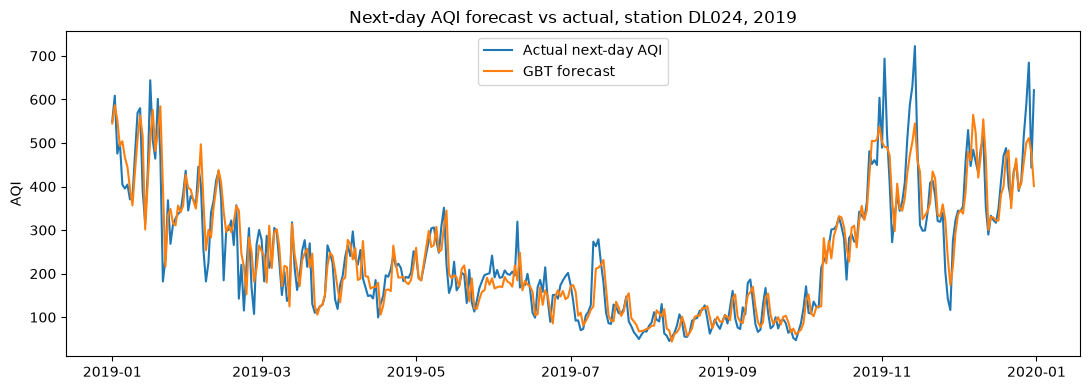

In [36]:
import pandas as pd
import matplotlib.pyplot as plt

# 1) Feature importances
imp = pd.Series(gbt.featureImportances.toArray(), index=fcols).sort_values(ascending=False)
print(imp.round(3))

# 2) MAE by season: GBT vs persistence
te_all = te19.unionByName(te20)
season = (F.when(F.col("month").isin(12, 1, 2), "Winter")
           .when(F.col("month").isin(3, 4, 5), "Summer")
           .when(F.col("month").isin(6, 7, 8, 9), "Monsoon")
           .otherwise("Post-monsoon"))

(gbt.transform(te_all).withColumn("season", season)
 .groupBy("season")
 .agg(F.count("*").alias("rows"),
      F.round(F.avg(F.abs(F.col("prediction") - F.col("next_AQI"))), 1).alias("GBT_MAE"),
      F.round(F.avg(F.abs(F.col("AQI") - F.col("next_AQI"))), 1).alias("Persistence_MAE"),
      F.round(F.avg("next_AQI"), 1).alias("avg_AQI"))
 .show())

# 3) Forecast vs actual for one Delhi station, 2019
sid = (te19.filter(F.col("City") == "Delhi").groupBy("StationId").count()
       .orderBy(F.desc("count")).first()["StationId"])
p = (gbt.transform(te19.filter(F.col("StationId") == sid))
     .select("date", "next_AQI", "prediction").orderBy("date").toPandas())

plt.figure(figsize=(11, 4))
plt.plot(p["date"], p["next_AQI"], label="Actual next-day AQI")
plt.plot(p["date"], p["prediction"], label="GBT forecast")
plt.title(f"Next-day AQI forecast vs actual, station {sid}, 2019")
plt.ylabel("AQI"); plt.legend(); plt.tight_layout(); plt.show()

In [38]:
import os
os.makedirs("results", exist_ok=True)

# City ranking (AQI-based, cleaned data)
city_rank = (
    df5.filter(F.col("AQI").isNotNull())
    .groupBy("City")
    .agg(F.count("*").alias("readings"),
         F.round(F.avg("AQI"), 1).alias("avg_AQI"),
         F.round(F.avg("PM25"), 1).alias("avg_PM25"))
    .filter(F.col("readings") >= 10000)
    .orderBy(F.desc("avg_AQI"))
)
city_rank.show(30)

# City by season (AQI-based, cleaned data)
season_tbl = (
    df5.filter(F.col("City").isin("Delhi", "Mumbai", "Bengaluru", "Chennai", "Kolkata", "Lucknow"))
    .groupBy("City").pivot("season", ["Winter", "Summer", "Monsoon", "Post-monsoon"])
    .agg(F.round(F.avg("AQI"), 1))
)
season_tbl.show()

# Save for dashboard and report
city_rank.toPandas().to_csv("results/city_ranking.csv", index=False)
season_tbl.toPandas().to_csv("results/city_season_aqi.csv", index=False)
covid.toPandas().to_csv("results/covid_by_city.csv", index=False)
diwali_res.toPandas().to_csv("results/diwali_by_city.csv", index=False)
hourly.to_csv("results/hourly_pm25.csv", index=False)

(gbt.transform(te_all)
 .select("StationId", "City", "date", "next_AQI", "prediction")
 .toPandas().to_csv("results/forecast_predictions.csv", index=False))

print(os.listdir("results"))

+------------------+--------+-------+--------+
|              City|readings|avg_AQI|avg_PM25|
+------------------+--------+-------+--------+
|             Delhi|  812215|  236.6|   110.1|
|           Lucknow|  120777|  217.0|   110.0|
|             Patna|   47459|  212.9|   102.3|
|          Gurugram|   52914|  210.8|   104.7|
|           Talcher|   15008|  177.6|    65.5|
|        Jorapokhar|   17430|  160.0|    64.0|
|      Brajrajnagar|   16047|  151.4|    66.8|
|          Guwahati|   11740|  140.2|    61.6|
|            Jaipur|   70494|  134.6|    55.0|
|           Kolkata|   70173|  132.6|    58.8|
|          Amritsar|   25840|  120.5|    54.4|
|     Visakhapatnam|   26766|  117.7|    48.3|
|           Chennai|  111696|  112.8|    48.3|
|            Mumbai|   90119|  103.7|    37.4|
|         Hyderabad|  163603|  100.5|    44.4|
|         Amaravati|   19377|   95.6|    38.8|
|         Bengaluru|  219523|   91.4|    34.4|
|Thiruvananthapuram|   27265|   75.1|    28.6|
+------------

/home/swarika/aqi-env/lib/python3.14/site-packages/pyspark/sql/pandas/conversion.py:298: FutureWarning: PySpark does not yet fully support pandas >= 3.0.0. Some features may not work correctly. It is recommended to use pandas < 3.0.0 for now.
  require_minimum_pandas_version()
/home/swarika/aqi-env/lib/python3.14/site-packages/pyspark/sql/pandas/conversion.py:298: FutureWarning: PySpark does not yet fully support pandas >= 3.0.0. Some features may not work correctly. It is recommended to use pandas < 3.0.0 for now.
  require_minimum_pandas_version()
/home/swarika/aqi-env/lib/python3.14/site-packages/pyspark/sql/pandas/conversion.py:298: FutureWarning: PySpark does not yet fully support pandas >= 3.0.0. Some features may not work correctly. It is recommended to use pandas < 3.0.0 for now.
  require_minimum_pandas_version()
/home/swarika/aqi-env/lib/python3.14/site-packages/pyspark/sql/pandas/conversion.py:298: FutureWarning: PySpark does not yet fully support pandas >= 3.0.0. Some featu

['diwali_by_city.csv', 'forecast_predictions.csv', 'city_ranking.csv', 'diwali_all_stations.csv', 'station_clusters.csv', '.ipynb_checkpoints', 'covid_by_city.csv', 'city_season_aqi.csv', 'hourly_pm25.csv']


In [39]:
import os
os.makedirs("results", exist_ok=True)

diwali_city = diwali_res if "diwali_res" in globals() else city_res
diwali_city.toPandas().to_csv("results/diwali_by_city.csv", index=False)

(x.groupBy("year").agg(
    F.countDistinct("StationId").alias("stations"),
    F.round(F.avg(F.when(F.col("phase") == "before", F.col("PM25"))), 1).alias("before"),
    F.round(F.avg(F.when(F.col("phase") == "after", F.col("PM25"))), 1).alias("after"))
 .toPandas().to_csv("results/diwali_all_stations.csv", index=False))

hourly.to_csv("results/hourly_pm25.csv", index=False)

(gbt.transform(te_all)
 .select("StationId", "City", "date", "next_AQI", "prediction")
 .toPandas().to_csv("results/forecast_predictions.csv", index=False))

print(sorted(os.listdir("results")))

/home/swarika/aqi-env/lib/python3.14/site-packages/pyspark/sql/pandas/conversion.py:298: FutureWarning: PySpark does not yet fully support pandas >= 3.0.0. Some features may not work correctly. It is recommended to use pandas < 3.0.0 for now.
  require_minimum_pandas_version()
/home/swarika/aqi-env/lib/python3.14/site-packages/pyspark/sql/pandas/conversion.py:298: FutureWarning: PySpark does not yet fully support pandas >= 3.0.0. Some features may not work correctly. It is recommended to use pandas < 3.0.0 for now.
  require_minimum_pandas_version()


['.ipynb_checkpoints', 'city_ranking.csv', 'city_season_aqi.csv', 'covid_by_city.csv', 'diwali_all_stations.csv', 'diwali_by_city.csv', 'forecast_predictions.csv', 'hourly_pm25.csv', 'station_clusters.csv']


/home/swarika/aqi-env/lib/python3.14/site-packages/pyspark/sql/pandas/conversion.py:298: FutureWarning: PySpark does not yet fully support pandas >= 3.0.0. Some features may not work correctly. It is recommended to use pandas < 3.0.0 for now.
  require_minimum_pandas_version()


In [40]:
import shutil
shutil.move("station_clusters.csv", "results/station_clusters.csv")

'results/station_clusters.csv'

In [41]:
import os, shutil
os.makedirs("results", exist_ok=True)

if os.path.exists("station_clusters.csv"):
    shutil.move("station_clusters.csv", "results/station_clusters.csv")

diwali_city = diwali_res if "diwali_res" in globals() else city_res
diwali_city.toPandas().to_csv("results/diwali_by_city.csv", index=False)

(x.groupBy("year").agg(
    F.countDistinct("StationId").alias("stations"),
    F.round(F.avg(F.when(F.col("phase") == "before", F.col("PM25"))), 1).alias("before"),
    F.round(F.avg(F.when(F.col("phase") == "after", F.col("PM25"))), 1).alias("after"))
 .toPandas().to_csv("results/diwali_all_stations.csv", index=False))

hourly.to_csv("results/hourly_pm25.csv", index=False)

(gbt.transform(te_all)
 .select("StationId", "City", "date", "next_AQI", "prediction")
 .toPandas().to_csv("results/forecast_predictions.csv", index=False))

for f in sorted(os.listdir("results")):
    print(f, os.path.getsize(f"results/{f}"), "bytes")

/home/swarika/aqi-env/lib/python3.14/site-packages/pyspark/sql/pandas/conversion.py:298: FutureWarning: PySpark does not yet fully support pandas >= 3.0.0. Some features may not work correctly. It is recommended to use pandas < 3.0.0 for now.
  require_minimum_pandas_version()
/home/swarika/aqi-env/lib/python3.14/site-packages/pyspark/sql/pandas/conversion.py:298: FutureWarning: PySpark does not yet fully support pandas >= 3.0.0. Some features may not work correctly. It is recommended to use pandas < 3.0.0 for now.
  require_minimum_pandas_version()


.ipynb_checkpoints 4096 bytes
city_ranking.csv 515 bytes
city_season_aqi.csv 224 bytes
covid_by_city.csv 543 bytes
diwali_all_stations.csv 126 bytes
diwali_by_city.csv 1930 bytes
forecast_predictions.csv 2054861 bytes
hourly_pm25.csv 2761 bytes
station_clusters.csv 9785 bytes


/home/swarika/aqi-env/lib/python3.14/site-packages/pyspark/sql/pandas/conversion.py:298: FutureWarning: PySpark does not yet fully support pandas >= 3.0.0. Some features may not work correctly. It is recommended to use pandas < 3.0.0 for now.
  require_minimum_pandas_version()


In [42]:
from pyspark.sql import SparkSession, functions as F

spark = SparkSession.builder.master("local[*]").appName("AQI-Analytics") \
    .config("spark.driver.memory", "4g").getOrCreate()
df5 = spark.read.parquet("clean_v3_parquet")
daily = spark.read.parquet("daily_parquet")

In [43]:
import os
for f in sorted(os.listdir("results")):
    print(f, os.path.getsize(f"results/{f}"), "bytes")

.ipynb_checkpoints 4096 bytes
city_ranking.csv 515 bytes
city_season_aqi.csv 224 bytes
covid_by_city.csv 543 bytes
diwali_all_stations.csv 126 bytes
diwali_by_city.csv 1930 bytes
forecast_predictions.csv 2054861 bytes
hourly_pm25.csv 2761 bytes
station_clusters.csv 9785 bytes


In [44]:
keep = city_rank.select("City")

hourly_all = (
    df5.join(keep, "City")
    .groupBy("City", "hour")
    .agg(F.round(F.avg("PM25"), 1).alias("pm25"))
    .orderBy("City", "hour")
    .toPandas()
)
hourly_all.to_csv("results/hourly_pm25.csv", index=False)

season_all = (
    df5.join(keep, "City")
    .groupBy("City")
    .pivot("season", ["Winter", "Summer", "Monsoon", "Post-monsoon"])
    .agg(F.round(F.avg("AQI"), 1))
    .toPandas()
)
season_all.to_csv("results/city_season_aqi.csv", index=False)

print(hourly_all["City"].nunique(), "cities")
print(sorted(hourly_all["City"].unique()))

/home/swarika/aqi-env/lib/python3.14/site-packages/pyspark/sql/pandas/conversion.py:298: FutureWarning: PySpark does not yet fully support pandas >= 3.0.0. Some features may not work correctly. It is recommended to use pandas < 3.0.0 for now.
  require_minimum_pandas_version()
/home/swarika/aqi-env/lib/python3.14/site-packages/pyspark/sql/pandas/conversion.py:298: FutureWarning: PySpark does not yet fully support pandas >= 3.0.0. Some features may not work correctly. It is recommended to use pandas < 3.0.0 for now.
  require_minimum_pandas_version()


18 cities
['Amaravati', 'Amritsar', 'Bengaluru', 'Brajrajnagar', 'Chennai', 'Delhi', 'Gurugram', 'Guwahati', 'Hyderabad', 'Jaipur', 'Jorapokhar', 'Kolkata', 'Lucknow', 'Mumbai', 'Patna', 'Talcher', 'Thiruvananthapuram', 'Visakhapatnam']
